# Lab 03: Computer Vision Prototyping & Object Detection Pipeline


In [15]:
import os, time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("images", exist_ok=True)
os.makedirs("results", exist_ok=True)

IMG_TRAFFIC = "images/traffic.jpeg"
IMG_INDUSTRIAL = "images/industrial.jpeg"
IMG_MEDICAL = "images/xray.jpeg"
IMG_DETECT = "images/street.jpeg"      # any image with people/cars for Task 4
IMG_SHELF = "images/shelf.jpeg"        # crowded shelf with bottles/apples
IMG_SECURITY = "images/security.jpeg"  # surveillance image with people

def bgr2rgb(im):
    return cv2.cvtColor(im, cv2.COLOR_BGR2RGB)

def load_or_synth(path, kind):
    """Load an image; if missing, synthesise a stand-in so the notebook runs."""
    im = cv2.imread(path)
    if im is not None:
        return im
    print(f"[info] {path} not found -> using synthetic '{kind}' image")
    rng = np.random.default_rng(0)
    if kind == "traffic":
        im = np.full((1080, 1920, 3), 90, np.uint8)
        cv2.rectangle(im, (0, 600), (1920, 1080), (60, 60, 60), -1)
        for i in range(6):
            x = 150 + i * 300
            cv2.rectangle(im, (x, 700), (x + 180, 800), tuple(int(c) for c in rng.integers(40, 255, 3)), -1)
    elif kind == "industrial":
        im = np.full((480, 640, 3), 170, np.uint8)
        cv2.rectangle(im, (80, 80), (560, 400), (200, 200, 200), -1)
        for (cx, cy, r) in [(200, 200, 40), (380, 260, 55), (470, 150, 30)]:
            cv2.circle(im, (cx, cy), r, (30, 90, 170), -1)  # rust-orange in BGR
        im = cv2.add(im, rng.integers(0, 15, im.shape, dtype=np.uint8))
    elif kind == "medical":
        im = np.zeros((512, 512, 3), np.uint8)
        cv2.ellipse(im, (256, 256), (180, 220), 0, 0, 360, (120, 120, 120), -1)
        cv2.ellipse(im, (200, 250), (60, 100), 0, 0, 360, (60, 60, 60), -1)
        cv2.ellipse(im, (320, 250), (60, 100), 0, 0, 360, (60, 60, 60), -1)
    else:
        im = np.full((480, 640, 3), 120, np.uint8)
    return im

## Task 1 — Preprocessing pipeline for traffic surveillance

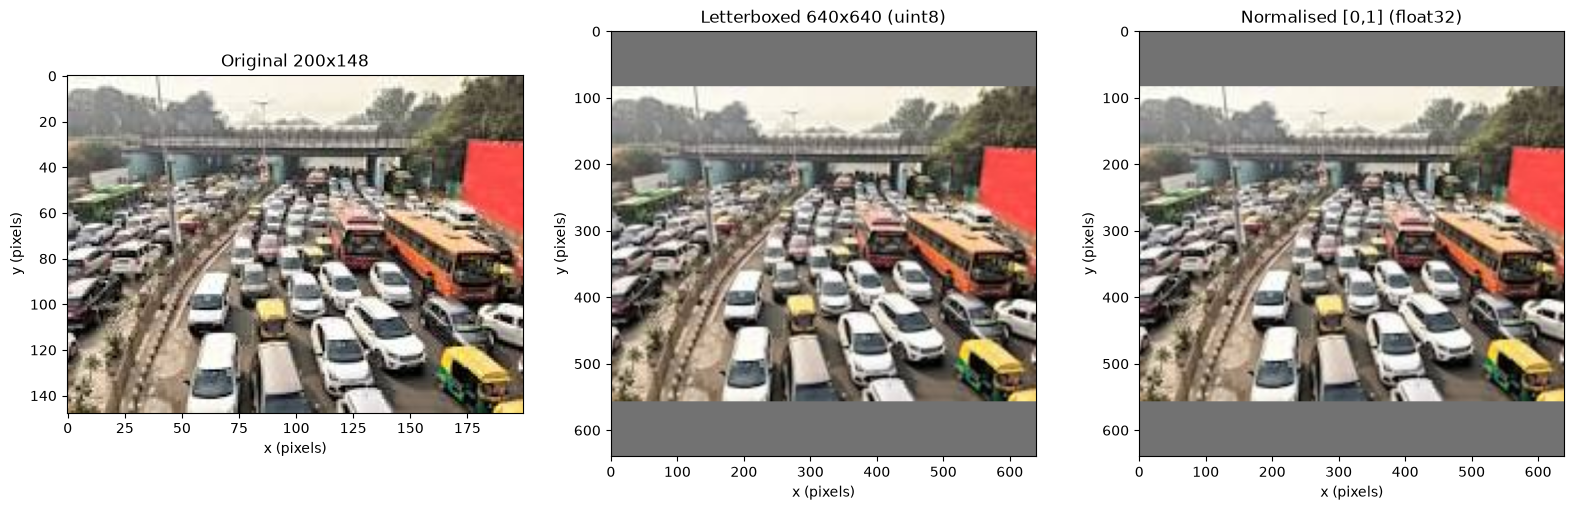

scale=3.2000, pad offset (left, top)=(0, 83)


,stage,shape,dtype,min,max,mean
0,original,"(148, 200, 3)",uint8,0.0,255.0,133.076700
1,letterboxed,"(640, 640, 3)",uint8,0.0,255.0,128.037188
2,normalised,"(640, 640, 3)",float32,0.0,1.0,0.502107


In [16]:
def letterbox(img, size=640, pad_color=(114, 114, 114)):
    """Resize keeping aspect ratio, pad to size x size."""
    h, w = img.shape[:2]
    scale = min(size / h, size / w)
    nh, nw = int(round(h * scale)), int(round(w * scale))
    interp = cv2.INTER_AREA if scale < 1 else cv2.INTER_LINEAR
    resized = cv2.resize(img, (nw, nh), interpolation=interp)
    top = (size - nh) // 2
    left = (size - nw) // 2
    out = np.full((size, size, 3), pad_color, np.uint8)
    out[top:top + nh, left:left + nw] = resized
    return out, scale, (left, top)

orig = load_or_synth(IMG_TRAFFIC, "traffic")
boxed, scale, offset = letterbox(orig, 640)
norm = boxed.astype(np.float32) / 255.0

fig, ax = plt.subplots(1, 3, figsize=(16, 5))
ax[0].imshow(bgr2rgb(orig));  ax[0].set_title(f"Original {orig.shape[1]}x{orig.shape[0]}")
ax[1].imshow(bgr2rgb(boxed)); ax[1].set_title("Letterboxed 640x640 (uint8)")
ax[2].imshow(cv2.cvtColor(norm, cv2.COLOR_BGR2RGB)); ax[2].set_title("Normalised [0,1] (float32)")
for a in ax:
    a.set_xlabel("x (pixels)"); a.set_ylabel("y (pixels)")
plt.tight_layout(); plt.show()

stats = pd.DataFrame({
    "stage": ["original", "letterboxed", "normalised"],
    "shape": [orig.shape, boxed.shape, norm.shape],
    "dtype": [str(orig.dtype), str(boxed.dtype), str(norm.dtype)],
    "min": [orig.min(), boxed.min(), float(norm.min())],
    "max": [orig.max(), boxed.max(), float(norm.max())],
    "mean": [orig.mean(), boxed.mean(), float(norm.mean())],
})
print(f"scale={scale:.4f}, pad offset (left, top)={offset}")
stats

## Task 2 — Defect detection via colour space + thresholding

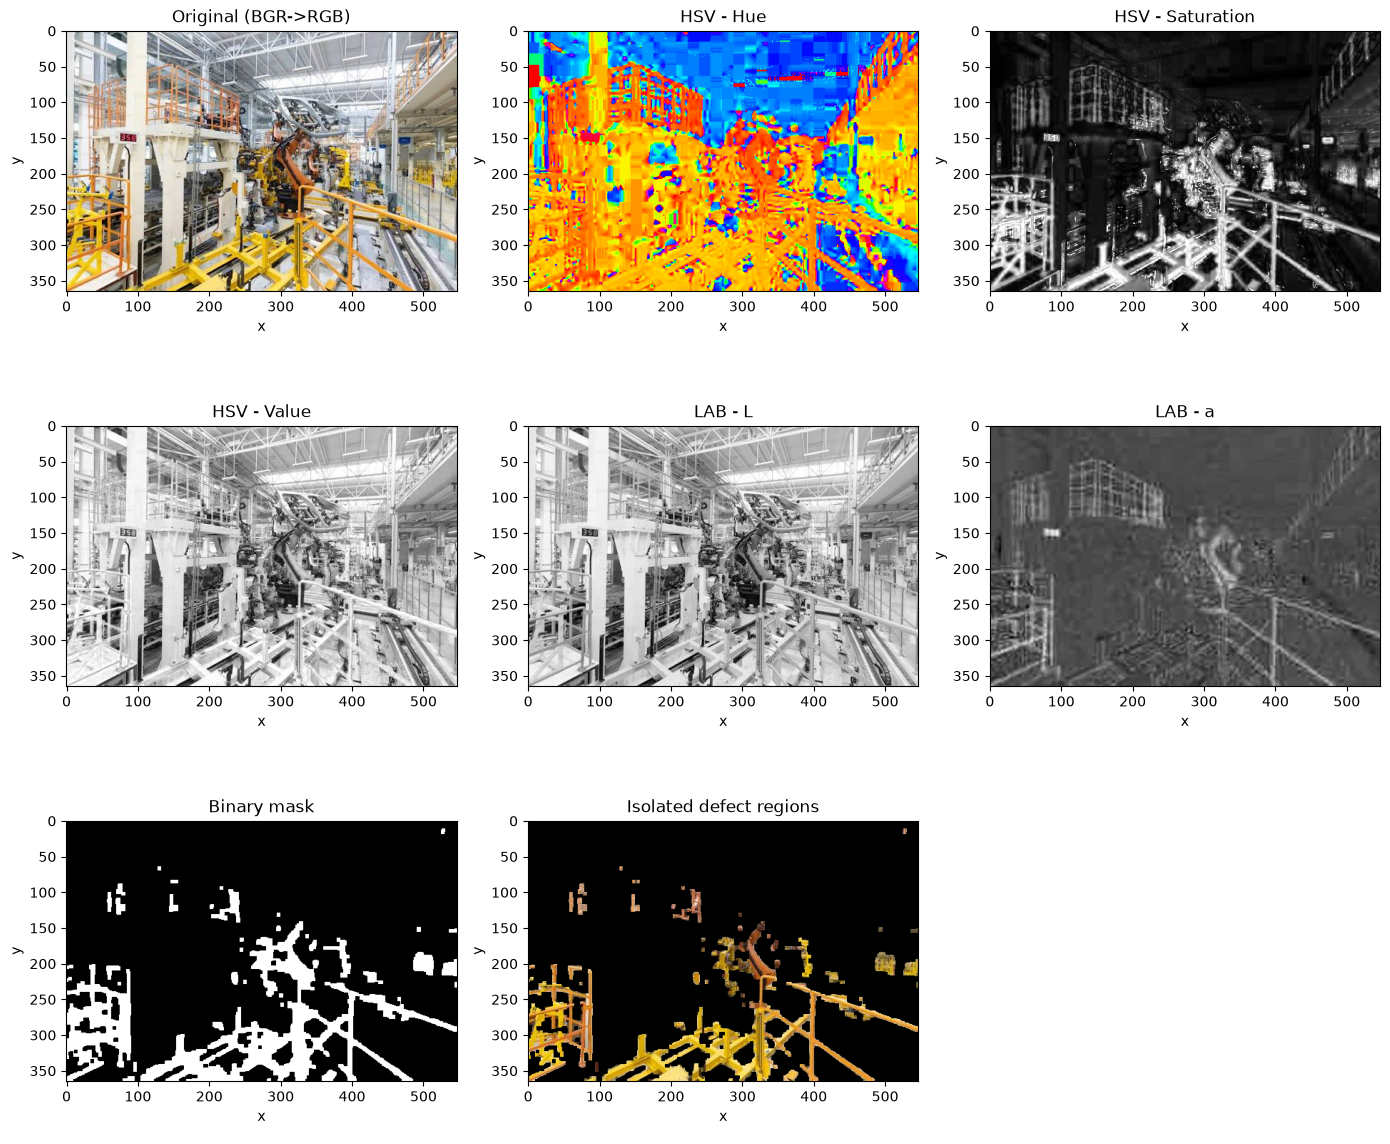

Defect pixels: 32120 (16.09% of image)


In [17]:
img = load_or_synth(IMG_INDUSTRIAL, "industrial")
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)

# Rust / orange-brown range in OpenCV HSV (H: 0-179). Tune for your image.
lower = np.array([5, 80, 60])
upper = np.array([25, 255, 255])

mask = cv2.inRange(hsv, lower, upper)
_, mask_bin = cv2.threshold(mask, 127, 255, cv2.THRESH_BINARY)
kernel = np.ones((5, 5), np.uint8)
mask_bin = cv2.morphologyEx(mask_bin, cv2.MORPH_OPEN, kernel)   # remove speckle
mask_bin = cv2.morphologyEx(mask_bin, cv2.MORPH_CLOSE, kernel)  # fill holes
isolated = cv2.bitwise_and(img, img, mask=mask_bin)

fig, ax = plt.subplots(3, 3, figsize=(14, 12))
panels = [
    (bgr2rgb(img), "Original (BGR->RGB)", None),
    (hsv[:, :, 0], "HSV - Hue", "hsv"),
    (hsv[:, :, 1], "HSV - Saturation", "gray"),
    (hsv[:, :, 2], "HSV - Value", "gray"),
    (lab[:, :, 0], "LAB - L", "gray"),
    (lab[:, :, 1], "LAB - a", "gray"),
    (mask_bin, "Binary mask", "gray"),
    (bgr2rgb(isolated), "Isolated defect regions", None),
    (None, "", None),
]
for a, (data, title, cmap) in zip(ax.ravel(), panels):
    if data is None:
        a.axis("off"); continue
    a.imshow(data, cmap=cmap); a.set_title(title); a.set_xlabel("x"); a.set_ylabel("y")
plt.tight_layout(); plt.show()
print(f"Defect pixels: {int((mask_bin > 0).sum())} "
      f"({100 * (mask_bin > 0).mean():.2f}% of image)")

## Task 3 — Noise reduction + edge detection (medical imaging)

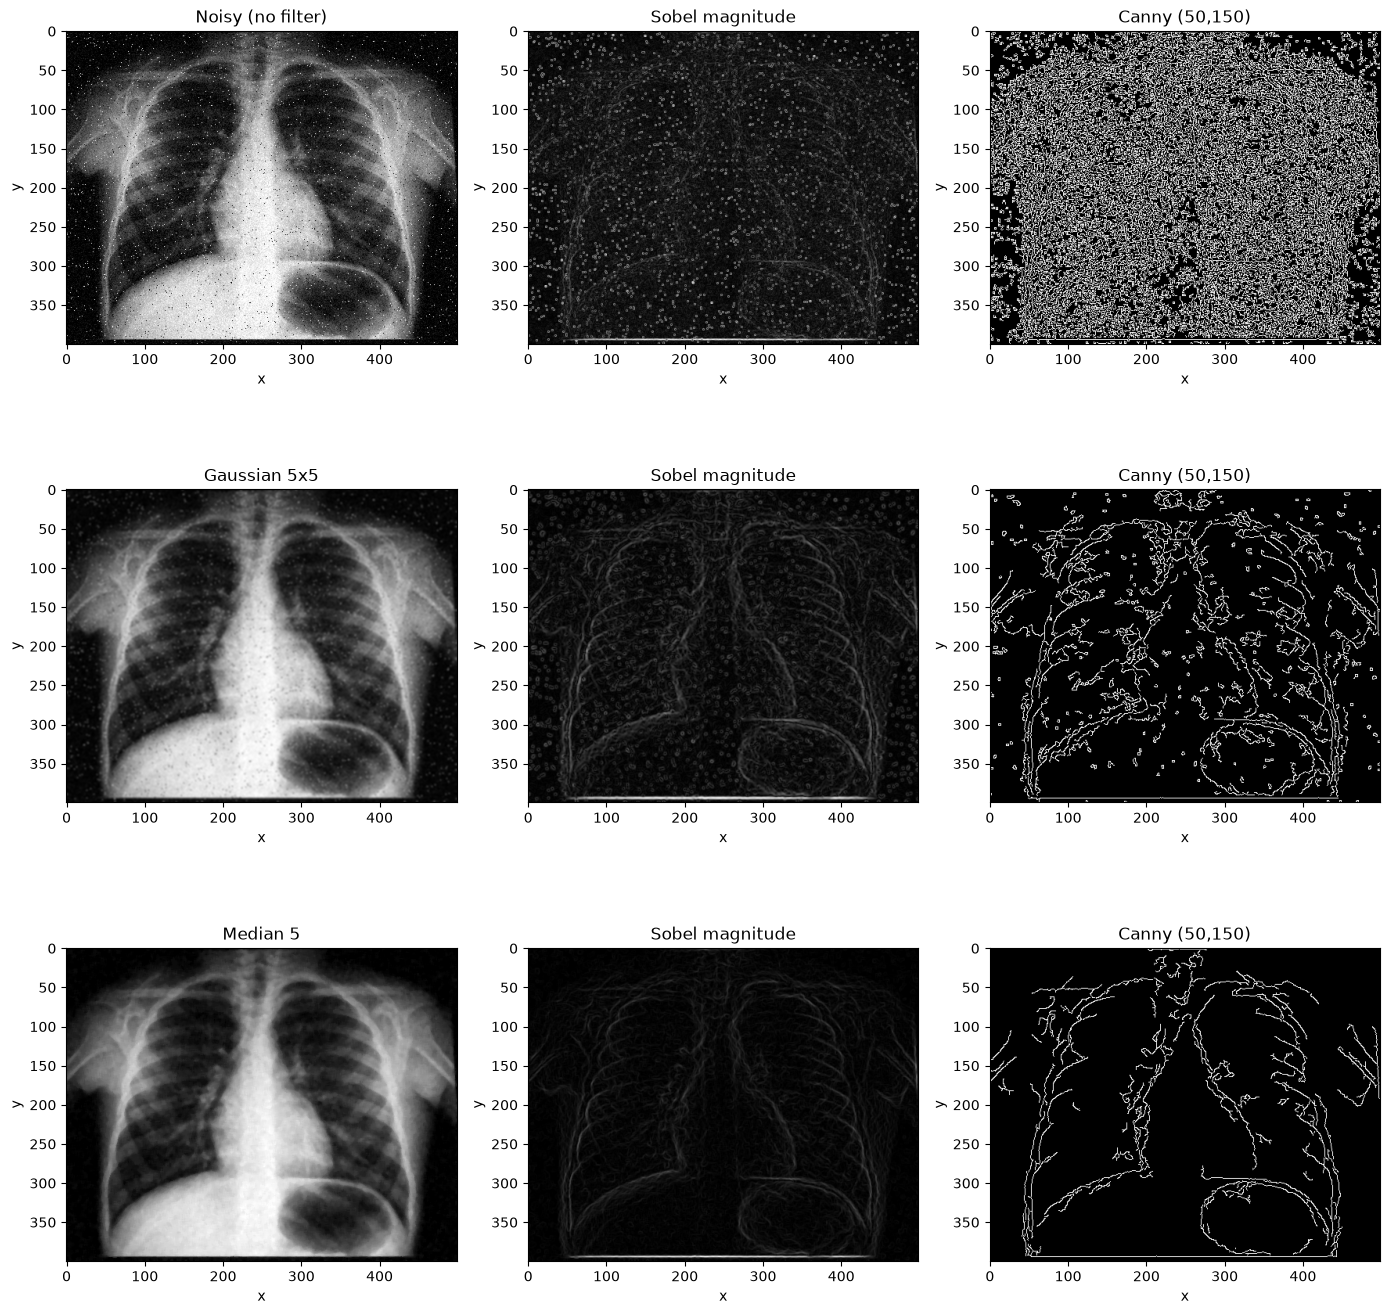

,filter,PSNR vs clean (dB),Sobel mean mag,Canny edge px,Precision,Recall,F1
0,Noisy (no filter),19.81,26.81,66131,0.051,0.548,0.094
1,Gaussian 5x5,29.59,20.52,15665,0.220,0.557,0.316
2,Median 5,33.00,10.18,8333,0.369,0.497,0.423


In [18]:
gray = cv2.imread(IMG_MEDICAL, cv2.IMREAD_GRAYSCALE)
if gray is None:
    gray = cv2.cvtColor(load_or_synth(IMG_MEDICAL, "medical"), cv2.COLOR_BGR2GRAY)

# Add noise so filters have something to remove (Gaussian + salt&pepper).
rng = np.random.default_rng(1)
noisy = gray.astype(np.float32) + rng.normal(0, 15, gray.shape)
sp = rng.random(gray.shape)
noisy[sp < 0.01] = 0
noisy[sp > 0.99] = 255
noisy = np.clip(noisy, 0, 255).astype(np.uint8)

filters = {
    "Noisy (no filter)": noisy,
    "Gaussian 5x5": cv2.GaussianBlur(noisy, (5, 5), 1.2),
    "Median 5": cv2.medianBlur(noisy, 5),
}

def sobel_mag(im):
    gx = cv2.Sobel(im, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(im, cv2.CV_64F, 0, 1, ksize=3)
    mag = np.sqrt(gx ** 2 + gy ** 2)
    return cv2.normalize(mag, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

T_LOW, T_HIGH = 50, 150
# Reference edges: Canny on the clean (un-noised) image.
ref_edges = cv2.Canny(cv2.GaussianBlur(gray, (5, 5), 1.2), T_LOW, T_HIGH) > 0

def psnr(a, b):
    mse = np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)
    return float("inf") if mse == 0 else 10 * np.log10(255 ** 2 / mse)

rows, maps = [], {}
for name, im in filters.items():
    sob = sobel_mag(im)
    can = cv2.Canny(im, T_LOW, T_HIGH)
    maps[name] = (sob, can)
    e = can > 0
    tp = np.logical_and(e, ref_edges).sum()
    prec = tp / max(e.sum(), 1)
    rec = tp / max(ref_edges.sum(), 1)
    f1 = 2 * prec * rec / max(prec + rec, 1e-9)
    rows.append({"filter": name,
                 "PSNR vs clean (dB)": round(psnr(gray, im), 2),
                 "Sobel mean mag": round(float(sob.mean()), 2),
                 "Canny edge px": int(e.sum()),
                 "Precision": round(prec, 3), "Recall": round(rec, 3), "F1": round(f1, 3)})

fig, ax = plt.subplots(3, 3, figsize=(14, 14))
for r, (name, im) in enumerate(filters.items()):
    sob, can = maps[name]
    ax[r, 0].imshow(im, cmap="gray");  ax[r, 0].set_title(name)
    ax[r, 1].imshow(sob, cmap="gray"); ax[r, 1].set_title("Sobel magnitude")
    ax[r, 2].imshow(can, cmap="gray"); ax[r, 2].set_title(f"Canny ({T_LOW},{T_HIGH})")
    for c in range(3):
        ax[r, c].set_xlabel("x"); ax[r, c].set_ylabel("y")
plt.tight_layout(); plt.show()
pd.DataFrame(rows)

Expected finding: median filtering removes salt-and-pepper noise while keeping
borders sharper than Gaussian blur, so it usually gives the higher edge F1 on
impulse noise; Gaussian is better for purely Gaussian noise.

## Task 4 — YOLO nano vs medium benchmark

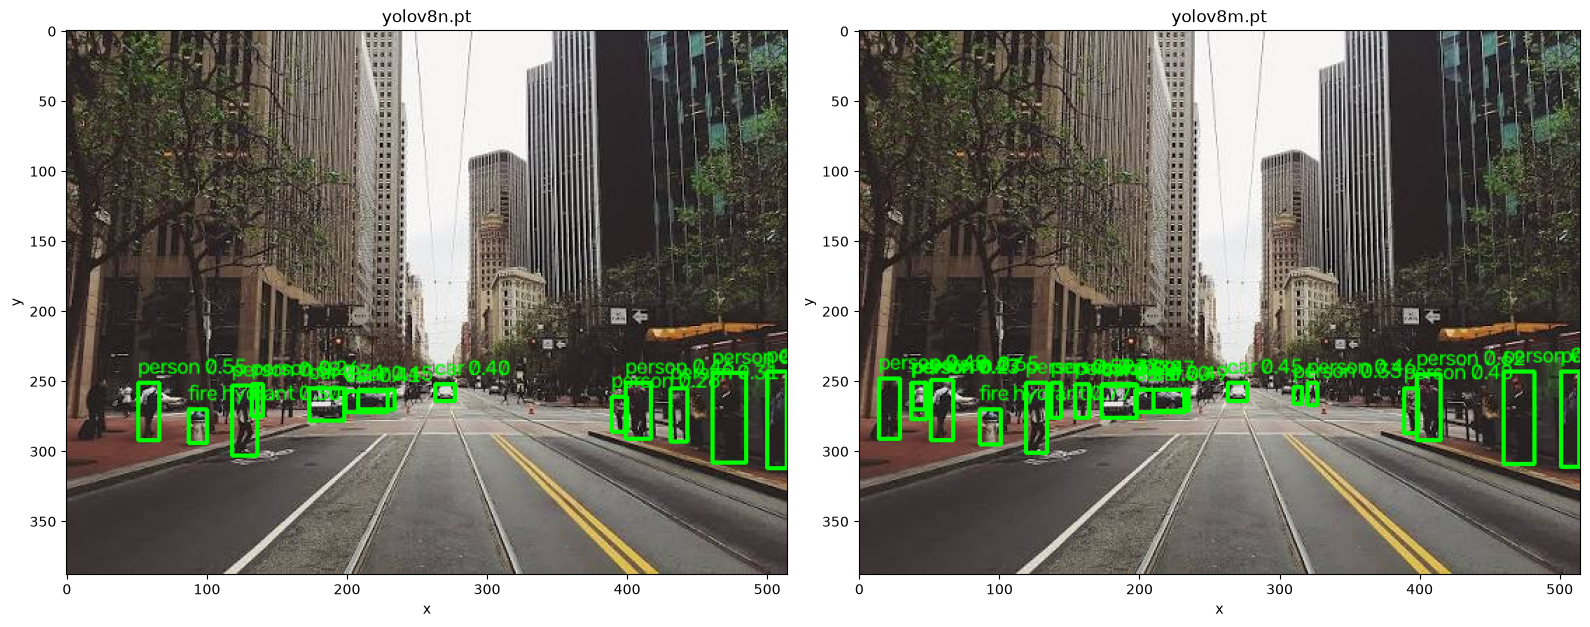

,model,latency (ms),detections,class counts,avg confidence
0,yolov8n.pt,164.5,13,"{'person': 8, 'car': 4, 'fire hydrant': 1}",0.405
1,yolov8m.pt,1010.8,19,"{'person': 13, 'car': 4, 'fire hydrant': 1, 't...",0.480


In [19]:
from ultralytics import YOLO

img4 = load_or_synth(IMG_DETECT, "street")
model_names = ["yolov8n.pt", "yolov8m.pt"]
models = {n: YOLO(n) for n in model_names}

def run_and_draw(model, image, conf=0.25, warmup=True):
    if warmup:
        model(image, verbose=False)
    t0 = time.perf_counter()
    res = model(image, conf=conf, verbose=False)[0]
    latency_ms = (time.perf_counter() - t0) * 1000
    out = image.copy()
    dets = []
    for b in res.boxes:
        x1, y1, x2, y2 = map(int, b.xyxy[0].tolist())
        c, k = float(b.conf[0]), int(b.cls[0])
        label = f"{res.names[k]} {c:.2f}"
        dets.append({"class": res.names[k], "conf": c, "box": (x1, y1, x2, y2)})
        cv2.rectangle(out, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(out, label, (x1, max(y1 - 6, 12)), cv2.FONT_HERSHEY_SIMPLEX,
                    0.5, (0, 255, 0), 1, cv2.LINE_AA)
    return out, dets, latency_ms

results, table = {}, []
for n, m in models.items():
    out, dets, ms = run_and_draw(m, img4)
    results[n] = out
    counts = pd.Series([d["class"] for d in dets]).value_counts().to_dict()
    table.append({"model": n, "latency (ms)": round(ms, 1),
                  "detections": len(dets), "class counts": counts,
                  "avg confidence": round(np.mean([d["conf"] for d in dets]), 3) if dets else 0.0})

fig, ax = plt.subplots(1, 2, figsize=(16, 7))
for a, n in zip(ax, model_names):
    a.imshow(bgr2rgb(results[n])); a.set_title(n); a.set_xlabel("x"); a.set_ylabel("y")
plt.tight_layout(); plt.show()
pd.DataFrame(table)

## Task 5 — Class-filtered retail inventory counting

Whole-image detections (conf>0.05):
 bottle        97
book           1
toothbrush     1


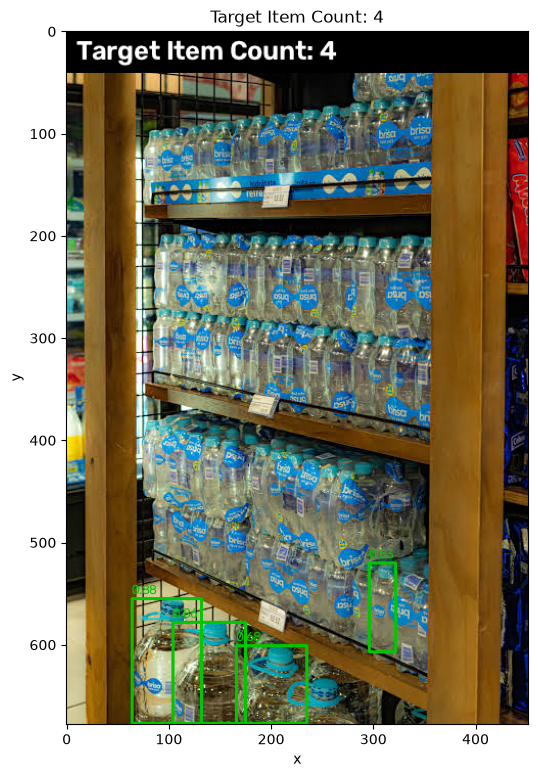

In [28]:
TARGET_IDS = {39}        # 39 = bottle, 47 = apple
CONF_THRES = 0.50        # lab requirement; for dense shelves try 0.30-0.35 and say so in your report
TILE, OVERLAP = 640, 0.30

shelf = load_or_synth(IMG_SHELF, "shelf")
model = YOLO("yolov8m.pt")

# Diagnostic: what does the model see on the whole image?
full = model(shelf, conf=0.05, imgsz=1280, iou=0.8, verbose=False)[0]
seen = pd.Series([full.names[int(b.cls[0])] for b in full.boxes]).value_counts()
print("Whole-image detections (conf>0.05):\n", seen.to_string() if len(seen) else "nothing")

def tiled_detect(model, img, tile=640, overlap=0.3, conf=0.05, iou_merge=0.5):
    H, W = img.shape[:2]
    step = max(int(tile * (1 - overlap)), 1)
    ys = list(range(0, max(H - tile, 0) + 1, step))
    xs = list(range(0, max(W - tile, 0) + 1, step))
    if H > tile and ys[-1] + tile < H: ys.append(H - tile)
    if W > tile and xs[-1] + tile < W: xs.append(W - tile)

    boxes, scores = [], []
    def collect(res, dx=0, dy=0):
        for b in res.boxes:
            if int(b.cls[0]) in TARGET_IDS:
                x1, y1, x2, y2 = b.xyxy[0].tolist()
                boxes.append([x1 + dx, y1 + dy, x2 - x1, y2 - y1])
                scores.append(float(b.conf[0]))

    collect(full)                                   # whole-image pass
    for y in ys:
        for x in xs:
            crop = img[y:y + tile, x:x + tile]
            r = model(crop, conf=conf, imgsz=tile, iou=0.8, verbose=False)[0]
            collect(r, x, y)

    if not boxes:
        return []
    keep = np.array(cv2.dnn.NMSBoxes(boxes, scores, conf, iou_merge)).flatten()
    return [(boxes[i], scores[i]) for i in keep]    # merge duplicates across tiles

dets = tiled_detect(model, shelf, TILE, OVERLAP)

out = shelf.copy()
count = 0
for (x, y, w, h), c in dets:
    if c > CONF_THRES:
        count += 1
        cv2.rectangle(out, (int(x), int(y)), (int(x + w), int(y + h)), (0, 200, 0), 2)
        cv2.putText(out, f"{c:.2f}", (int(x), max(int(y) - 4, 12)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 200, 0), 1, cv2.LINE_AA)

banner = f"Target Item Count: {count}"
cv2.rectangle(out, (0, 0), (out.shape[1], 40), (0, 0, 0), -1)
cv2.putText(out, banner, (10, 28), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 255, 255), 2, cv2.LINE_AA)
cv2.imwrite("results/task5_shelf.jpg", out)

plt.figure(figsize=(14, 9)); plt.imshow(bgr2rgb(out)); plt.title(banner)
plt.xlabel("x"); plt.ylabel("y"); plt.show()

## Task 6 — ROI intrusion alerting

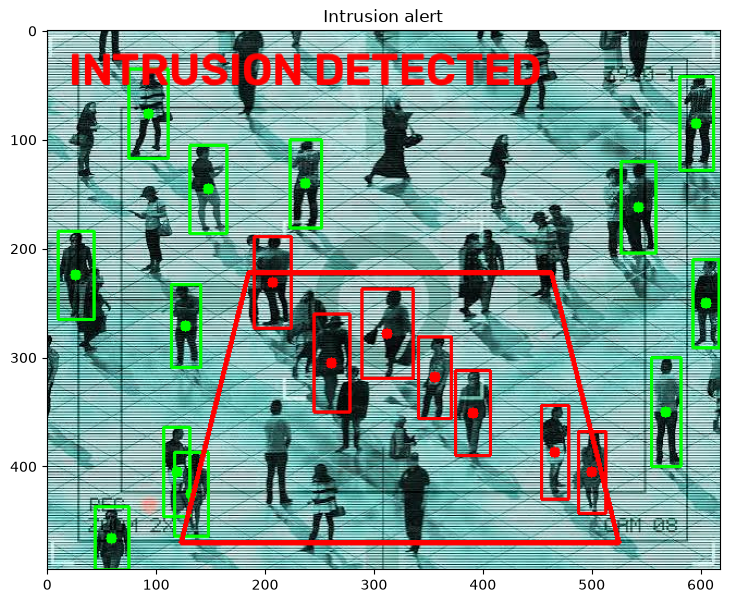

In [21]:
sec = load_or_synth(IMG_SECURITY, "security")
h, w = sec.shape[:2]
# Polygon ROI as fractions of image size so it fits any resolution. Edit as needed.
roi = np.array([[0.30, 0.45], [0.75, 0.45], [0.85, 0.95], [0.20, 0.95]])
roi = (roi * [w, h]).astype(np.int32)

model = YOLO("yolov8n.pt")
res = model(sec, classes=[0], conf=0.40, verbose=False)[0]   # class 0 = person

intrusion = False
out = sec.copy()
for b in res.boxes:
    x1, y1, x2, y2 = map(int, b.xyxy[0].tolist())
    xc, yc = (x1 + x2) // 2, (y1 + y2) // 2
    inside = cv2.pointPolygonTest(roi.reshape(-1, 1, 2), (float(xc), float(yc)), False) >= 0
    intrusion |= inside
    col = (0, 0, 255) if inside else (0, 255, 0)
    cv2.rectangle(out, (x1, y1), (x2, y2), col, 2)
    cv2.circle(out, (xc, yc), 5, col, -1)

roi_col = (0, 0, 255) if intrusion else (0, 255, 0)
cv2.polylines(out, [roi.reshape(-1, 1, 2)], True, roi_col, 3)
if intrusion:
    cv2.putText(out, "INTRUSION DETECTED", (20, 50), cv2.FONT_HERSHEY_SIMPLEX,
                1.4, (0, 0, 255), 4, cv2.LINE_AA)
else:
    cv2.putText(out, "Area clear", (20, 50), cv2.FONT_HERSHEY_SIMPLEX,
                1.2, (0, 255, 0), 3, cv2.LINE_AA)
cv2.imwrite("results/task6_intrusion.jpg", out)

plt.figure(figsize=(10, 7)); plt.imshow(bgr2rgb(out))
plt.title("Intrusion alert" if intrusion else "No intrusion"); plt.show()